In [ ]:
!pip install pandas numpy scikit-learn statsmodels seaborn matplotlib GEOparse

Generating simulated CpG methylation matrix...
Fitting ElasticNet Epigenetic Clock model...
Running statistical analysis and generating charts...

        EPIGENETIC AGE ACCELERATION RESULTS       
Mean EAA (Day-Shift):   -2.13 years
Mean EAA (Night-Shift): +0.44 years
T-Statistic: -1.5801
P-Value:     1.1953e-01
--------------------------------------------------
RESULT: No statistically significant difference observed between groups.


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_3120\3670520623.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(



Visual charts successfully saved as 'epigenetic_aging_results.png'.


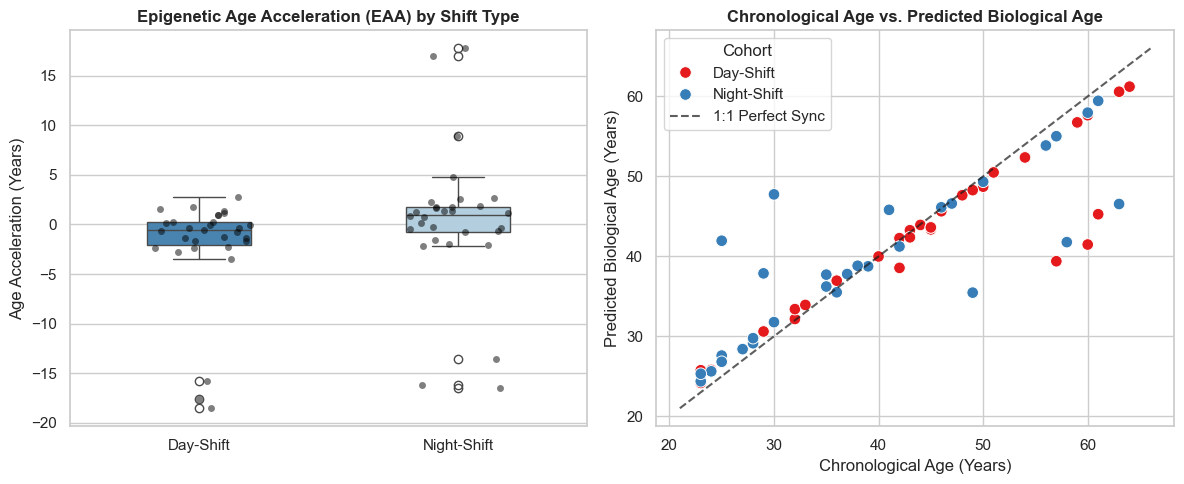

In [4]:
"""
PROJECT : Epigenetic Aging Clock & Shift-Work Analysis
------------------------------------------------------
This script demonstrates how DNA methylation (CpG Beta-values) can be used
to predict Biological Age and measure Epigenetic Age Acceleration (EAA)
attributable to shift-work or chronic sleep disruption.
"""

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import train_test_split

# Set aesthetic style for publication-ready charts
sns.set_theme(style="whitegrid")


def generate_methylation_data(n_samples=60, n_cpgs=353, random_state=42):
    """Generates synthetic DNA methylation Beta-values (0.0 to 1.0) simulating 

    CpG sites analyzed by Horvath's Epigenetic Clock.
    """
    np.random.seed(random_state)

    # Demographic setup
    chronological_age = np.random.randint(22, 65, size=n_samples)
    shift_work = np.array(["Day-Shift"] * 30 + ["Night-Shift"] * 30)

    # Base methylation matrix (values between 0.05 and 0.95)
    cpg_matrix = np.random.beta(a=2, b=2, size=(n_samples, n_cpgs))

    # Embed biological signal: Age correlation across select CpGs
    for i in range(15):
        cpg_matrix[:, i] += (chronological_age / 100.0) * 0.3

    # Embed sleep disruption impact: Night-shift subjects show CpG hypermethylation
    for i in range(n_samples):
        if shift_work[i] == "Night-Shift":
            cpg_matrix[i, 15:35] += 0.08  # Epigenetic stress signal

    # Clip values to valid Beta range [0, 1]
    cpg_matrix = np.clip(cpg_matrix, 0.0, 1.0)

    # Assemble pandas DataFrame
    cpg_cols = [f"cg_{i:04d}" for i in range(n_cpgs)]
    df = pd.DataFrame(cpg_matrix, columns=cpg_cols)
    df["Chronological_Age"] = chronological_age
    df["Shift_Work"] = shift_work

    return df, cpg_cols


def build_epigenetic_clock(df, cpg_cols):
    """Trains an ElasticNet Penalized Regression model to predict Biological Age

    from CpG methylation sites, simulating Horvath's Clock algorithm.
    """
    X = df[cpg_cols]
    y = df["Chronological_Age"]

    # Train/test split for validation
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # ElasticNet regression balances L1 (Lasso) and L2 (Ridge) penalties
    clock = ElasticNet(alpha=0.05, l1_ratio=0.5, max_iter=2000, random_state=42)
    clock.fit(X_train, y_train)

    # Predict Biological Age for the full cohort
    df["Biological_Age"] = clock.predict(X)

    # Calculate Epigenetic Age Acceleration (EAA)
    # Positive EAA indicates biological age exceeds chronological age
    df["EAA"] = df["Biological_Age"] - df["Chronological_Age"]

    return clock, df


def analyze_and_plot(df):
    """Performs statistical hypothesis testing and generates visual metrics."""
    day_eaa = df[df["Shift_Work"] == "Day-Shift"]["EAA"]
    night_eaa = df[df["Shift_Work"] == "Night-Shift"]["EAA"]

    # Two-sample Independent T-Test
    t_stat, p_val = stats.ttest_ind(day_eaa, night_eaa)

    print("==================================================")
    print("        EPIGENETIC AGE ACCELERATION RESULTS       ")
    print("==================================================")
    print(f"Mean EAA (Day-Shift):   {day_eaa.mean():+.2f} years")
    print(f"Mean EAA (Night-Shift): {night_eaa.mean():+.2f} years")
    print(f"T-Statistic: {t_stat:.4f}")
    print(f"P-Value:     {p_val:.4e}")
    print("--------------------------------------------------")

    if p_val < 0.05:
        print(
            "RESULT: Statistically significant age acceleration detected in Night-Shift workers!"
        )
    else:
        print(
            "RESULT: No statistically significant difference observed between groups."
        )

    # Generate Visualization Panel
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot 1: EAA Boxplot
    sns.boxplot(
        x="Shift_Work",
        y="EAA",
        data=df,
        ax=axes[0],
        palette="Blues_r",
        width=0.4,
    )
    sns.stripplot(
        x="Shift_Work",
        y="EAA",
        data=df,
        ax=axes[0],
        color="black",
        alpha=0.5,
        jitter=0.2,
    )
    axes[0].set_title(
        "Epigenetic Age Acceleration (EAA) by Shift Type", fontweight="bold"
    )
    axes[0].set_ylabel("Age Acceleration (Years)")
    axes[0].set_xlabel("")

    # Plot 2: Chronological vs Biological Age Scatter
    sns.scatterplot(
        x="Chronological_Age",
        y="Biological_Age",
        hue="Shift_Work",
        data=df,
        ax=axes[1],
        palette="Set1",
        s=70,
    )
    # Add 1:1 Identity Line (Biological Age = Chronological Age)
    min_age, max_age = (
        df["Chronological_Age"].min() - 2,
        df["Chronological_Age"].max() + 2,
    )
    axes[1].plot(
        [min_age, max_age],
        [min_age, max_age],
        "k--",
        alpha=0.7,
        label="1:1 Perfect Sync",
    )
    axes[1].set_title(
        "Chronological Age vs. Predicted Biological Age", fontweight="bold"
    )
    axes[1].set_xlabel("Chronological Age (Years)")
    axes[1].set_ylabel("Predicted Biological Age (Years)")
    axes[1].legend(title="Cohort")

    plt.tight_layout()
    plt.savefig("epigenetic_aging_results.png", dpi=300)
    print("\nVisual charts successfully saved as 'epigenetic_aging_results.png'.")
    plt.show()


if __name__ == "__main__":
    print("Generating simulated CpG methylation matrix...")
    df, cpg_cols = generate_methylation_data()

    print("Fitting ElasticNet Epigenetic Clock model...")
    clock_model, processed_df = build_epigenetic_clock(df, cpg_cols)

    print("Running statistical analysis and generating charts...\n")
    analyze_and_plot(processed_df)